In [1]:
import pandas as pd
import numpy as np
import umap
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.cluster import KMeans
from wordcloud import WordCloud

c:\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df=pd.read_csv('dataset.csv')
df.head()

,Heading,Body,Category,URL
0,free speech not hate speech madras high court ...,madras high court issue significant remark ami...,law,https://www.indiatoday.in/law/high-courts/stor...
1,comment take context say us cop mock indian st...,seattle police officer guild friday come defen...,world,https://www.indiatoday.in/world/story/indian-s...
2,first meeting one nation one election committe...,first official meeting one nation one election...,india,https://www.indiatoday.in/india/story/one-nati...
3,us airlines flight depressurize midair plummet...,united airlines jet head rome turn around less...,world,https://www.indiatoday.in/world/story/us-fligh...
4,terrorist kill security force foil infiltratio...,three terrorist kill infiltration bid foil sec...,india,https://www.indiatoday.in/india/story/one-terr...


In [3]:
df.shape

(11583, 4)

In [4]:
corpus=list(df['Heading'])

In [5]:
corpus[8775]

'switch shoe quota kota'

In [6]:
corpus_embeddings=np.load('embeddings_headings.npy')

In [7]:
print(corpus_embeddings.shape)

(11583, 768)


In [8]:
# reduce the size of the embeddings using UMAP
reduced_embeddings = umap.UMAP(n_components=2, n_neighbors=100, min_dist=0.02).fit_transform(corpus_embeddings)
print(reduced_embeddings.shape)

# put the values of the two dimensions inside the dataframe
df["x"] = reduced_embeddings[:, 0]
df["y"] = reduced_embeddings[:, 1]

# substring of the full text, for visualization purposes
df["text_short"] = df["Heading"].str[:100]

(11583, 2)


In [9]:
reduced_embeddings

array([[ 4.121452 , 13.71243  ],
       [ 5.1715937, 13.216642 ],
       [ 2.2453568, 14.896557 ],
       ...,
       [ 2.8906205, 14.469297 ],
       [ 7.1107893, 11.611894 ],
       [ 3.7655547, 13.135024 ]], dtype=float32)

In [10]:
# scatter plot
hover_data = {
    "text_short": True,
    "x": False,
    "y": False
}
fig = px.scatter(df, x="x", y="y", template="plotly_dark",
                   title="Embeddings", hover_data=hover_data)
fig.update_layout(showlegend=False)
fig.show()

In [11]:
num_clusters=10
clustering_model=KMeans(n_clusters=num_clusters)
clustering_model.fit(reduced_embeddings)
cluster_assignment=clustering_model.labels_

c:\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [12]:
cluster_assignment

array([3, 6, 8, ..., 8, 5, 3])

In [13]:
cluster_df = pd.DataFrame(corpus, columns = ['corpus'])
cluster_df['cluster'] = cluster_assignment
cluster_df.head()

,corpus,cluster
0,free speech not hate speech madras high court ...,3
1,comment take context say us cop mock indian st...,6
2,first meeting one nation one election committe...,8
3,us airlines flight depressurize midair plummet...,6
4,terrorist kill security force foil infiltratio...,6


In [14]:
desired_cluster = 0
selected_df = cluster_df[cluster_df['cluster'] == desired_cluster]
selected_df.head(15)

,corpus,cluster
16,biden not pardon son hunter find guilty gun ch...,0
26,india today archive america tilt towards pakistan,0
40,india race secure border china,0
49,bright brilliant determine amitabh kant praise...,0
56,belarus propose threeway cooperation russia no...,0
57,north koreas kim inspect russian nuclearcapabl...,0
60,kim jong un visit russias pacific fleet amid t...,0
63,canada defers trade mission india amid politic...,0
297,two russian cosmonaut launch space station ame...,0
313,kim jong un meet vladimir putin russian spacep...,0


In [15]:
selected_df.shape

(897, 2)

In [16]:
def word_cloud(pred_df,label):
    wc = ' '.join([text for text in pred_df['corpus'][pred_df['cluster'] == label]])
    wordcloud = WordCloud(width=800, height=500,
    random_state=21, max_font_size=110).generate(wc)
    fig7 = plt.figure(figsize=(10, 7))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis('off')

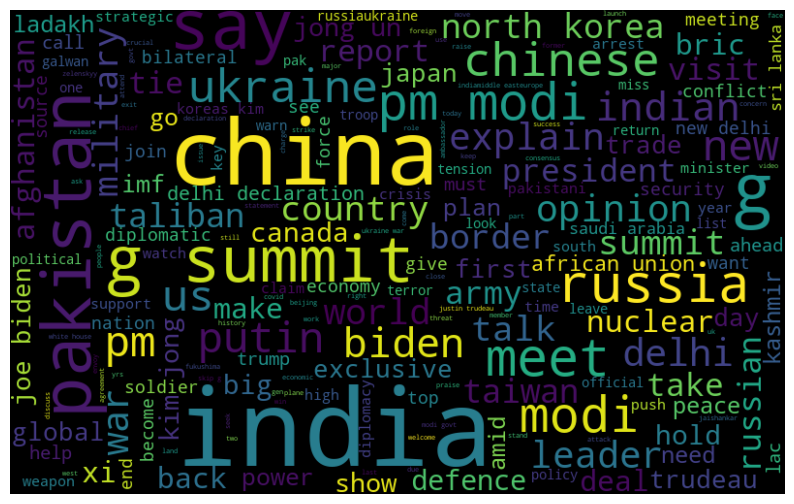

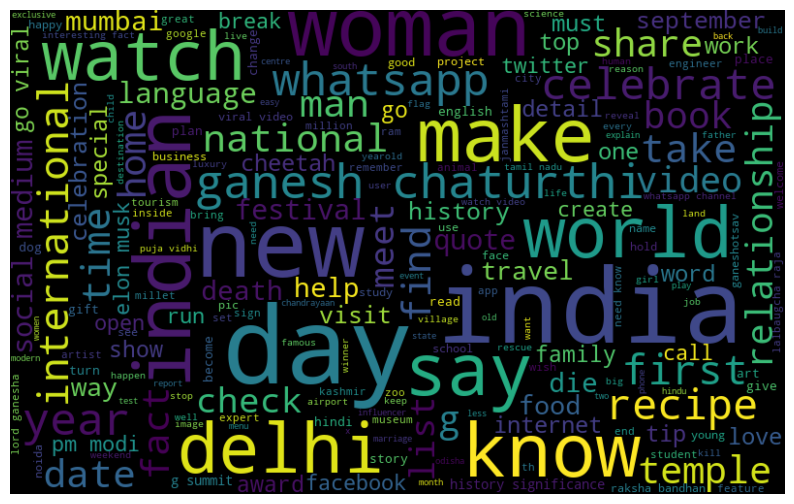

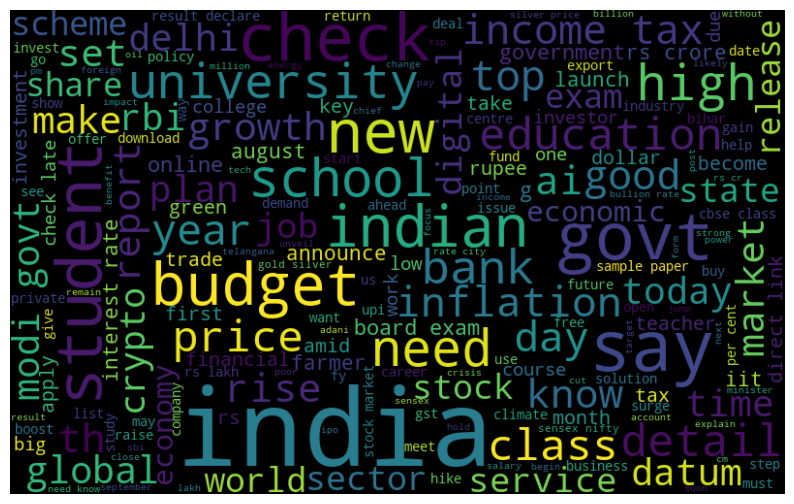

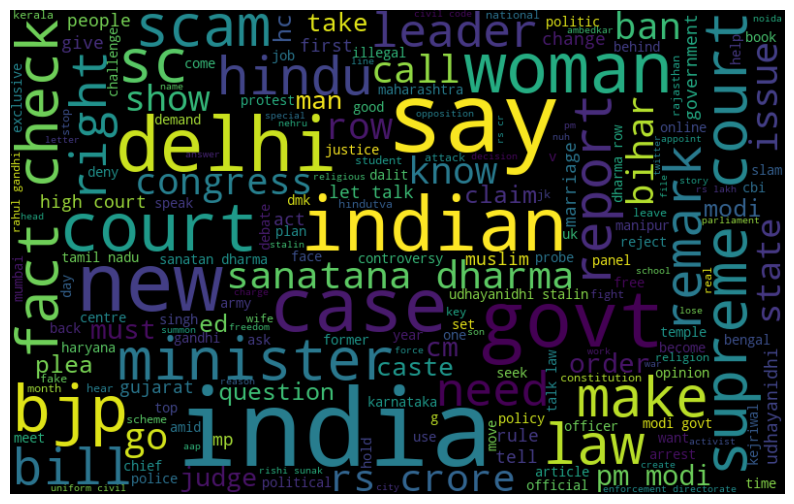

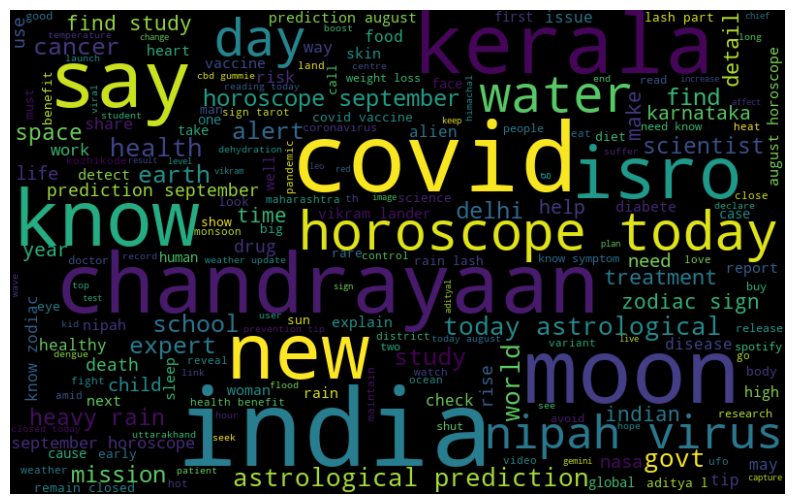

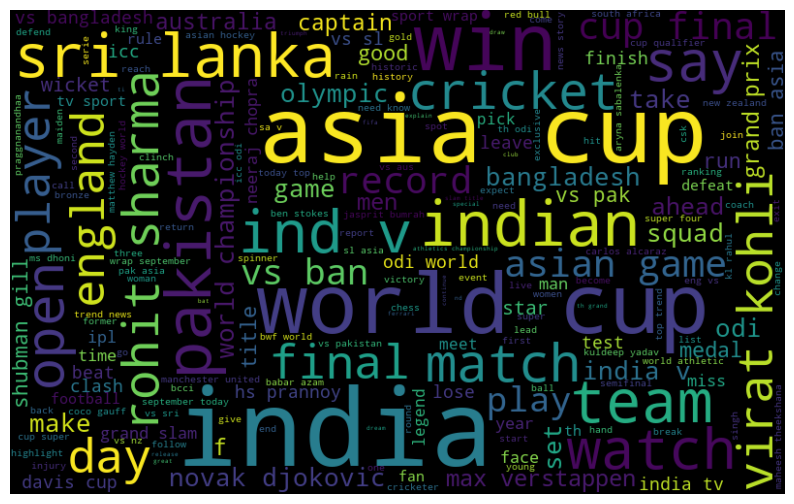

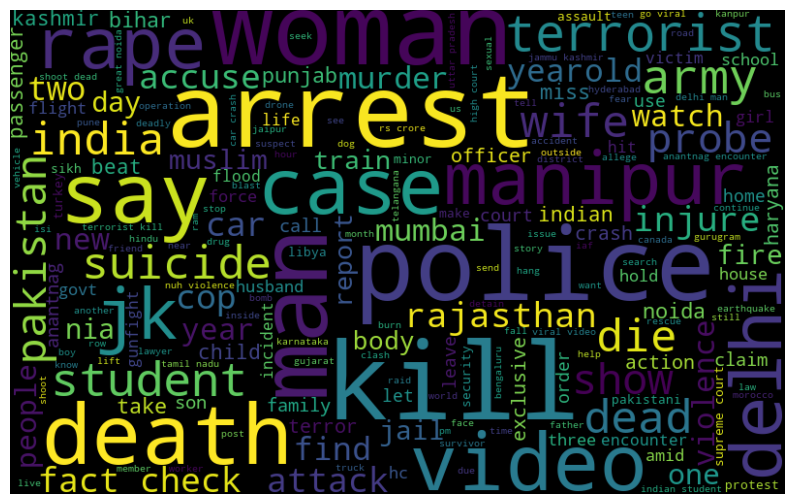

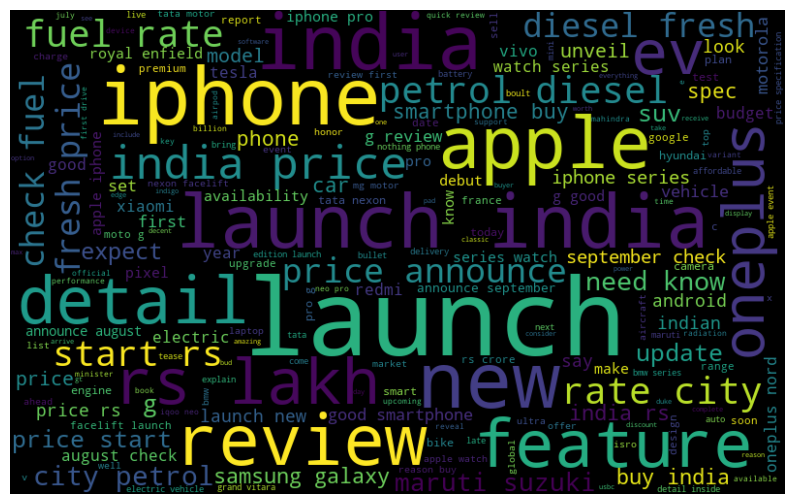

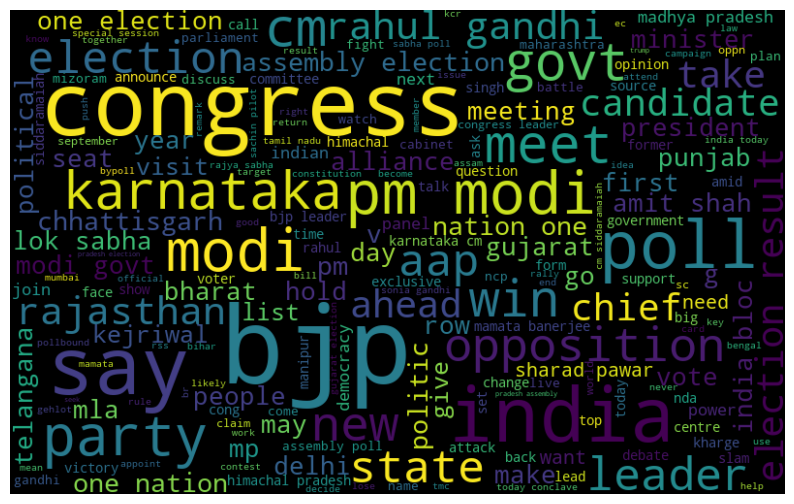

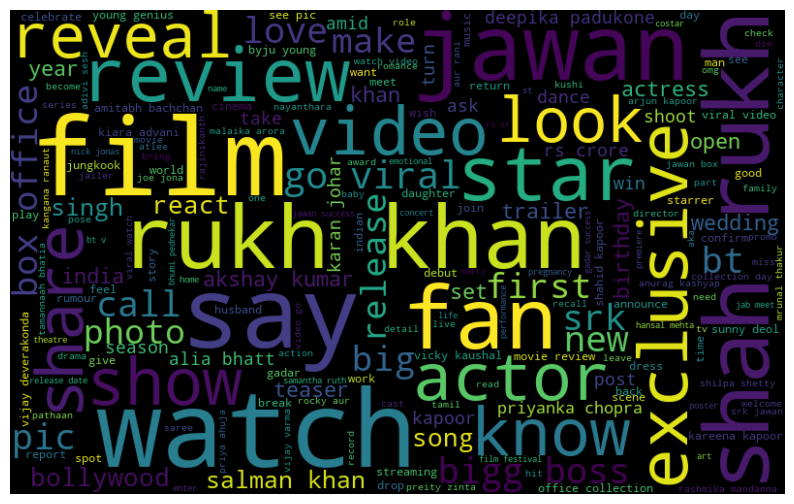

In [17]:
for i in range(10):
    word_cloud(cluster_df,i)

In [18]:
def categorize(label):
    if label==3:
        return 'Judiciary'
    elif label==9:
        return 'Entertainment'
    elif label==4:
        return 'Science'
    elif label==5:
        return 'Sports'
    elif label==8:
        return 'Politics'
    elif label==0:
        return 'International'
    elif label==7:
        return 'Technology'
    elif label==2:
        return 'Business'
    elif label==1:
        return 'Culture'
    elif label==6:
        return 'Crime'
    else:
        return label

In [19]:
cluster_df['Body']=df['Body']
cluster_df.head()

,corpus,cluster,Body
0,free speech not hate speech madras high court ...,3,madras high court issue significant remark ami...
1,comment take context say us cop mock indian st...,6,seattle police officer guild friday come defen...
2,first meeting one nation one election committe...,8,first official meeting one nation one election...
3,us airlines flight depressurize midair plummet...,6,united airlines jet head rome turn around less...
4,terrorist kill security force foil infiltratio...,6,three terrorist kill infiltration bid foil sec...


In [20]:
cluster_df['Category'] = cluster_df['cluster'].apply(categorize)
pd.unique(cluster_df['Category'])

array(['Judiciary', 'Crime', 'Politics', 'Science', 'Entertainment',
       'Sports', 'Culture', 'International', 'Business', 'Technology'],
      dtype=object)

In [21]:
cluster_df.head()

,corpus,cluster,Body,Category
0,free speech not hate speech madras high court ...,3,madras high court issue significant remark ami...,Judiciary
1,comment take context say us cop mock indian st...,6,seattle police officer guild friday come defen...,Crime
2,first meeting one nation one election committe...,8,first official meeting one nation one election...,Politics
3,us airlines flight depressurize midair plummet...,6,united airlines jet head rome turn around less...,Crime
4,terrorist kill security force foil infiltratio...,6,three terrorist kill infiltration bid foil sec...,Crime


In [22]:
del cluster_df['cluster']
cluster_df.head()

,corpus,Body,Category
0,free speech not hate speech madras high court ...,madras high court issue significant remark ami...,Judiciary
1,comment take context say us cop mock indian st...,seattle police officer guild friday come defen...,Crime
2,first meeting one nation one election committe...,first official meeting one nation one election...,Politics
3,us airlines flight depressurize midair plummet...,united airlines jet head rome turn around less...,Crime
4,terrorist kill security force foil infiltratio...,three terrorist kill infiltration bid foil sec...,Crime


In [23]:
cluster_df.rename(columns={'corpus': 'Heading'}, inplace=True)
cluster_df.head()

,Heading,Body,Category
0,free speech not hate speech madras high court ...,madras high court issue significant remark ami...,Judiciary
1,comment take context say us cop mock indian st...,seattle police officer guild friday come defen...,Crime
2,first meeting one nation one election committe...,first official meeting one nation one election...,Politics
3,us airlines flight depressurize midair plummet...,united airlines jet head rome turn around less...,Crime
4,terrorist kill security force foil infiltratio...,three terrorist kill infiltration bid foil sec...,Crime


In [26]:
cluster_df['URL']=df['URL']
cluster_df.head()

,Heading,Body,Category,URL
0,free speech not hate speech madras high court ...,madras high court issue significant remark ami...,Judiciary,https://www.indiatoday.in/law/high-courts/stor...
1,comment take context say us cop mock indian st...,seattle police officer guild friday come defen...,Crime,https://www.indiatoday.in/world/story/indian-s...
2,first meeting one nation one election committe...,first official meeting one nation one election...,Politics,https://www.indiatoday.in/india/story/one-nati...
3,us airlines flight depressurize midair plummet...,united airlines jet head rome turn around less...,Crime,https://www.indiatoday.in/world/story/us-fligh...
4,terrorist kill security force foil infiltratio...,three terrorist kill infiltration bid foil sec...,Crime,https://www.indiatoday.in/india/story/one-terr...


In [25]:
cluster_df.to_csv('labelled.csv', index=False)